# Import Library

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Membaca dan Memahami Data

In [3]:
data = pd.read_excel("KTP.xlsx", header=2)

print("Header Data")
print(data.head())

print("\nKolom Data")
print(data.columns)

print("\n Info Data")
data.info()

Header Data
  IDEM      KODE    WILAYAH          L          P        JML       WKTP  \
0    2     32.09    CIREBON  1280500.0  1243197.0  2523697.0  1849737.0   
1    3  32.09.01      WALED    32523.0    31452.0    63975.0    46755.0   
2    3  32.09.02    CILEDUG    25550.0    24743.0    50293.0    37872.0   
3    3  32.09.03     LOSARI    35296.0    34204.0    69500.0    51319.0   
4    3  32.09.04  PABEDILAN    33187.0    32642.0    65829.0    49292.0   

          %        KTP        %.1  ...      REKAM        %.3  BLM_REKAM  \
0       NaN  1829136.0        NaN  ...  1835196.0        NaN    14541.0   
1  2.527657    46292.0  99.009732  ...    46415.0  99.272805      340.0   
2  2.047426    37414.0  98.790663  ...    37567.0  99.194656      305.0   
3  2.774394    50762.0  98.914632  ...    50921.0  99.224459      398.0   
4  2.664811    48744.0  98.888258  ...    48910.0  99.225026      382.0   

        %.4    KTP_LK    KTP_PR      KTP.1  BLM_KTP_LK  BLM_KTP_PR   BLMKTP  
0       

# 2. Pemilihan Kolom yang Digunakan

In [16]:
df = pd.DataFrame({
    "KECAMATAN": data["WILAYAH"],
    "WKTP": data["WKTP"],
    "KTP": data["KTP"],
    "PERSEN_KTP": data["%.1"],
    "BLM_REKAM": data["BLM_REKAM"],
    "KTP_LK": data["KTP_LK"],
    "KTP_PR": data["KTP_PR"],
    "BLMKTP": data["BLMKTP"],
    "BLM_KTP_LK" : data["BLM_KTP_LK"],
    "BLM_KTP_PR" : data["BLM_KTP_PR"]
})

# 3. Data Cleaning

In [17]:
# A. Cek Missing Value
print("\nCek missing value")
print(df.isnull().values.any())

# Jumlah Data Sebelum Cleaning
print("\nJumlah data sebelum cleaning :", len(df))

# Menampilkan Seluruh Baris
print("\nData sebelum cleaning :")
print(df.head(45))

# B. Hapus Baris Agregat dan yang Tidak Diperlukan
df = df.dropna()
df = df.drop(index=41)

# Cek Kembali Missing Value
print("\nCek kembali missing value")
print(df.isnull().values.any())

# C. Reset index
df.reset_index(drop=True, inplace=True)
df.index = range(1, len(df) + 1)

# Jumlah Data Setelah Cleaning
print("\nJumlah data setelah cleaning :", len(df))

# Menampilkan Seluruh Baris
print("\nData setelah cleaning :")
print(df.head(40))

# D. Cek Tipe Data
print("\nTipe Data : ")
print(df.dtypes)


Cek missing value
True

Jumlah data sebelum cleaning : 45

Data sebelum cleaning :
        KECAMATAN       WKTP        KTP  PERSEN_KTP  BLM_REKAM    KTP_LK  \
0         CIREBON  1849737.0  1829136.0         NaN    14541.0  920709.0   
1           WALED    46755.0    46292.0   99.009732      340.0   23378.0   
2         CILEDUG    37872.0    37414.0   98.790663      305.0   18848.0   
3          LOSARI    51319.0    50762.0   98.914632      398.0   25505.0   
4       PABEDILAN    49292.0    48744.0   98.888258      382.0   24282.0   
5         BABAKAN    58950.0    58361.0   99.000848      401.0   28965.0   
6   KARANGSEMBUNG    29514.0    29193.0   98.912381      216.0   14487.0   
7      LEMAHABANG    45346.0    44786.0   98.765051      378.0   22501.0   
8   SUSUKAN LEBAK    32996.0    32616.0   98.848345      300.0   16448.0   
9          SEDONG    35014.0    34635.0   98.917576      250.0   17470.0   
10   ASTANAJAPURA    64169.0    63293.0   98.634855      659.0   32361.0   
11  

# 4. Ringkasan Data

In [18]:
print("\n===== RINGKASAN DATA =====")

# Hitung total dan persentase
total_wktp = df["WKTP"].sum()
total_ktp = df["KTP"].sum()
total_blmktp = df["BLMKTP"].sum()
total_blm_rekam = df["BLM_REKAM"].sum()
total_lk = df["KTP_LK"].sum()
total_pr = df["KTP_PR"].sum()

total_rekam = total_wktp - total_blm_rekam

persen_kepemilikan = (total_ktp / total_wktp) * 100
persen_belum_ktp = (total_blmktp / total_wktp) * 100
persen_rekam = (total_rekam / total_wktp) * 100
persen_belum_rekam = (total_blm_rekam / total_wktp) * 100
persen_lk = (total_lk / total_ktp) * 100
persen_pr = (total_pr / total_ktp) * 100

# Menampilkan hasil perhitungan
print("Jumlah Kecamatan :", len(df))

print("Total Wajib KTP-el :", f"{int(total_wktp):,}".replace(",", "."))
print("Total Memiliki KTP-el :", f"{int(total_ktp):,}".replace(",", "."))
print("Total Belum Memiliki KTP-el :", f"{int(total_blmktp):,}".replace(",", "."))
print("Total Sudah Rekam KTP-el :", f"{int(total_rekam):,}".replace(",", "."))
print("Total Belum Rekam KTP-el :", f"{int(total_blm_rekam):,}".replace(",", "."))
print("Total Pemilik KTP-el Laki-Laki :", f"{int(total_lk):,}".replace(",", "."))
print("Total Pemilik KTP-el Perempuan :", f"{int(total_pr):,}".replace(",", "."))
print("Persentase Kepemilikan KTP-el :", f"{persen_kepemilikan:.2f}%")
print("Persentase Belum Memiliki KTP-el :", f"{persen_belum_ktp:.2f}%")
print("Persentase Sudah Rekam KTP-el :", f"{persen_rekam:.2f}%")
print("Persentase Belum Rekam KTP-el :", f"{persen_belum_rekam:.2f}%")
print("Persentase Pemilik KTP-el Laki-Laki :", f"{persen_lk:.2f}%")
print("Persentase Pemilik KTP-el Perempuan :", f"{persen_pr:.2f}%")


===== RINGKASAN DATA =====
Jumlah Kecamatan : 40
Total Wajib KTP-el : 1.849.737
Total Memiliki KTP-el : 1.829.136
Total Belum Memiliki KTP-el : 20.601
Total Sudah Rekam KTP-el : 1.835.196
Total Belum Rekam KTP-el : 14.541
Total Pemilik KTP-el Laki-Laki : 920.709
Total Pemilik KTP-el Perempuan : 908.427
Persentase Kepemilikan KTP-el : 98.89%
Persentase Belum Memiliki KTP-el : 1.11%
Persentase Sudah Rekam KTP-el : 99.21%
Persentase Belum Rekam KTP-el : 0.79%
Persentase Pemilik KTP-el Laki-Laki : 50.34%
Persentase Pemilik KTP-el Perempuan : 49.66%


# 5. Grafik
## A. Gaya Grafik

In [38]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (13, 5)

## B. Grafik 1 : Kepemilikan KTP-el Terendah

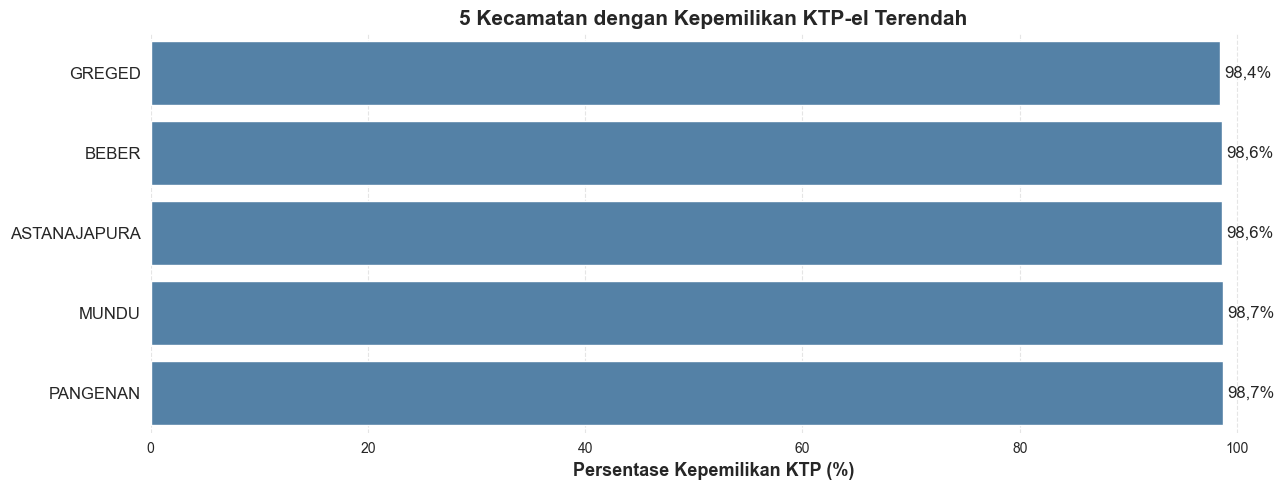

In [101]:
top_persen_rendah = df.sort_values(
    "PERSEN_KTP"
).head(5)

plt.figure()

ax = sns.barplot(
    data=top_persen_rendah,
    x="PERSEN_KTP",
    y="KECAMATAN",
    color="steelblue"
)

sns.despine(
    ax=ax,
    left=True,
    bottom=True
)

plt.title("5 Kecamatan dengan Kepemilikan KTP-el Terendah", fontsize=15, fontweight="bold")
plt.xlabel("Persentase Kepemilikan KTP (%)", fontsize=13, fontweight="bold")
plt.ylabel("")
plt.yticks(fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)

for p in ax.patches:
    ax.annotate(
        f"{p.get_width():.1f}%".replace(".", ","),
        (p.get_width(), p.get_y() + p.get_height()/2),
        va="center",
        fontsize=12,
        xytext=(3, 0),
        textcoords="offset points"
    )

plt.tight_layout()
#plt.savefig("grafik_1_persentase_kepemilikan_ktp.png", dpi=300, bbox_inches="tight")
plt.show()

## C. Grafik 2 : Belum Memiliki KTP-el Terbanyak

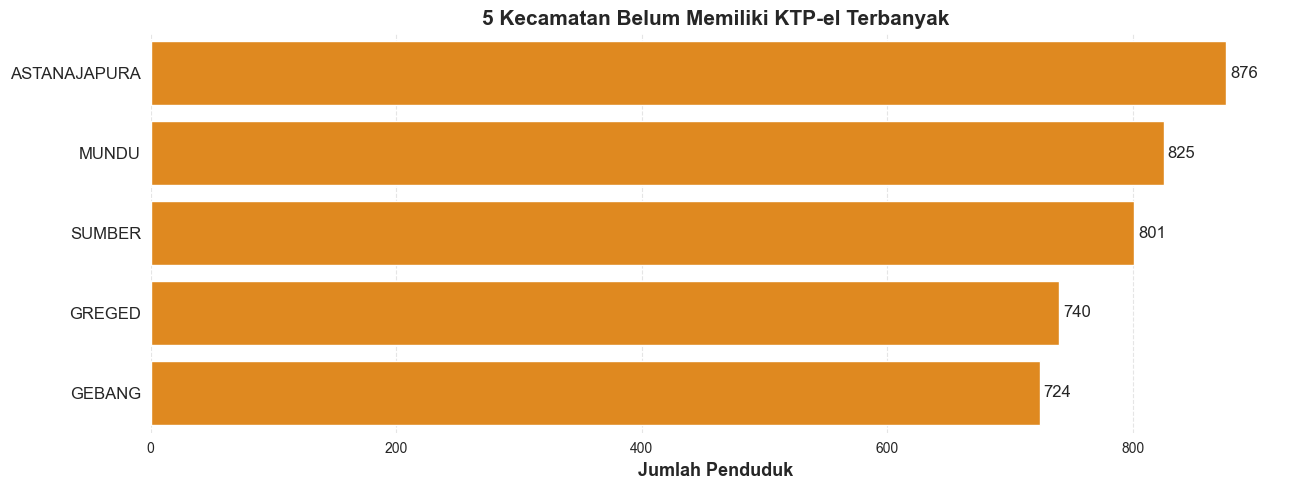

In [100]:
top_blmktp = df.sort_values(
    "BLMKTP",
    ascending=False
).head(5)

plt.figure()

ax = sns.barplot(
    data=top_blmktp,
    x="BLMKTP",
    y="KECAMATAN",
    color="darkorange"
)

sns.despine(
    ax=ax,
    left=True,
    bottom=True
)

plt.title("5 Kecamatan Belum Memiliki KTP-el Terbanyak", fontsize=15, fontweight="bold")
plt.xlabel("Jumlah Penduduk", fontsize=13, fontweight="bold")
plt.ylabel("")
plt.yticks(fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_width()):,}".replace(",", "."),
        (p.get_width(), p.get_y() + p.get_height()/2),
        va="center",
        fontsize=12,
        xytext=(3, 0),
        textcoords="offset points"
    )

plt.tight_layout()
#plt.savefig("grafik_2_belum_memiliki_ktp.png", dpi=300, bbox_inches="tight")
plt.show()

## D. Grafik 3 : Belum Rekam KTP-el Terbanyak

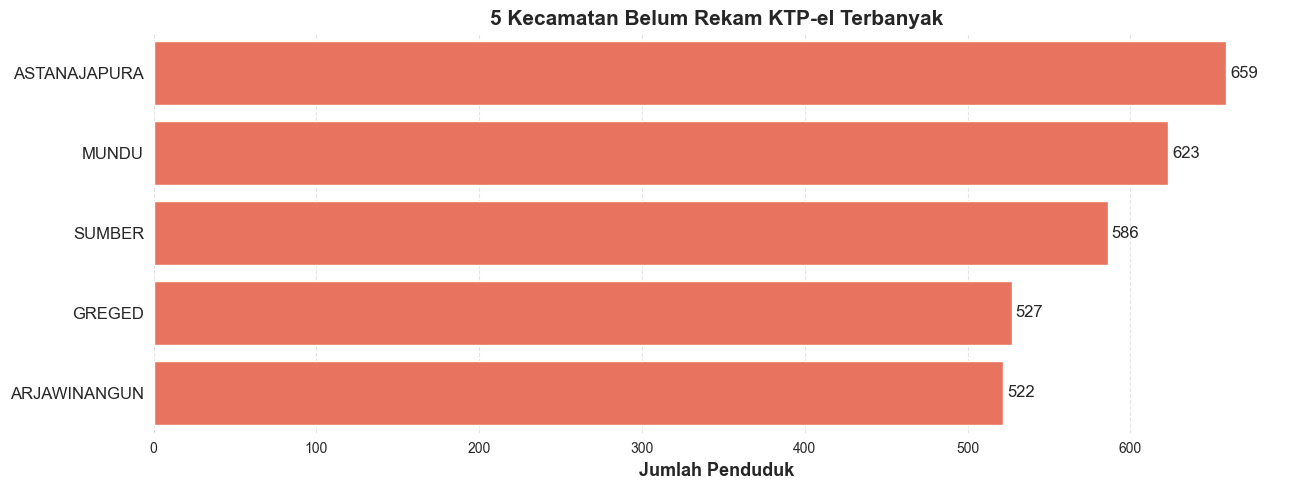

In [99]:
top_blmrekam = df.sort_values(
    "BLM_REKAM",
    ascending=False
).head(5)

plt.figure()

ax = sns.barplot(
    data=top_blmrekam,
    x="BLM_REKAM",
    y="KECAMATAN",
    color="tomato"
)

sns.despine(
    ax=ax,
    left=True,
    bottom=True
)

plt.title("5 Kecamatan Belum Rekam KTP-el Terbanyak", fontsize=15, fontweight="bold")
plt.xlabel("Jumlah Penduduk", fontsize=13, fontweight="bold")
plt.ylabel("")
plt.yticks(fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_width()):,}".replace(",", "."),
        (p.get_width(), p.get_y() + p.get_height()/2),
        va="center",
        fontsize=12,
        xytext=(3, 0),
        textcoords="offset points"
    )

plt.tight_layout()
#plt.savefig("grafik_3_belum_rekam.png", dpi=300, bbox_inches="tight")
plt.show()

## E. Grafik 4 : Kepemilikan KTP-el di Kabupaten Cirebon

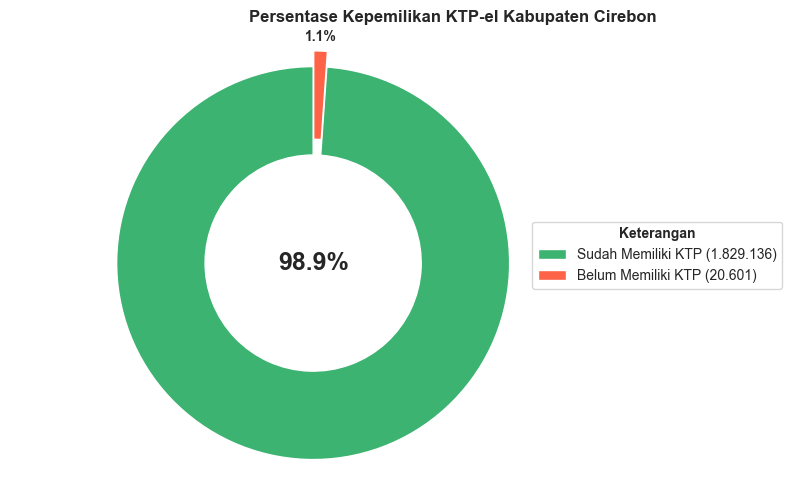

In [86]:
sudah_memiliki = df["KTP"].sum()
belum_memiliki = df["BLMKTP"].sum()

total = sudah_memiliki + belum_memiliki

persentase_ktp = (sudah_memiliki / total) * 100

plt.figure(figsize=(8, 5))

wedges, texts, autotexts = plt.pie(
    [sudah_memiliki, belum_memiliki],
    autopct="%1.1f%%",
    startangle=90,
    colors=["mediumseagreen", "tomato"],
    explode=(0, 0.08),
    wedgeprops=dict(width=0.45),
    pctdistance=1.08
)

# Ukuran teks persentase
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight("bold")

autotexts[0].set_text("")
autotexts[1].set_y(1.15)

# Teks di tengah donut
plt.text(
    0,
    0,
    f"{persentase_ktp:.1f}%",
    ha="center",
    va="center",
    fontsize=18,
    fontweight="bold"
)

# Keterangan
legend = plt.legend(
    wedges,
    [
        f"Sudah Memiliki KTP ({sudah_memiliki:,.0f})".replace(",", "."),
        f"Belum Memiliki KTP ({belum_memiliki:,.0f})".replace(",", ".")
    ],
    title="Keterangan",
    loc="center left",
    bbox_to_anchor=(0.85, 0.5)
)
legend.get_title().set_fontweight("bold")

plt.title("Persentase Kepemilikan KTP-el Kabupaten Cirebon", fontsize=12, fontweight="bold", x=0.73)
plt.axis("equal")
plt.tight_layout()
#plt.savefig("grafik_4_kepemilikan_ktp.png", dpi=300, bbox_inches="tight")
plt.show()

## F. Grafik 5 : Kepemilikan KTP-el Berdasarkan Jenis Kelamin

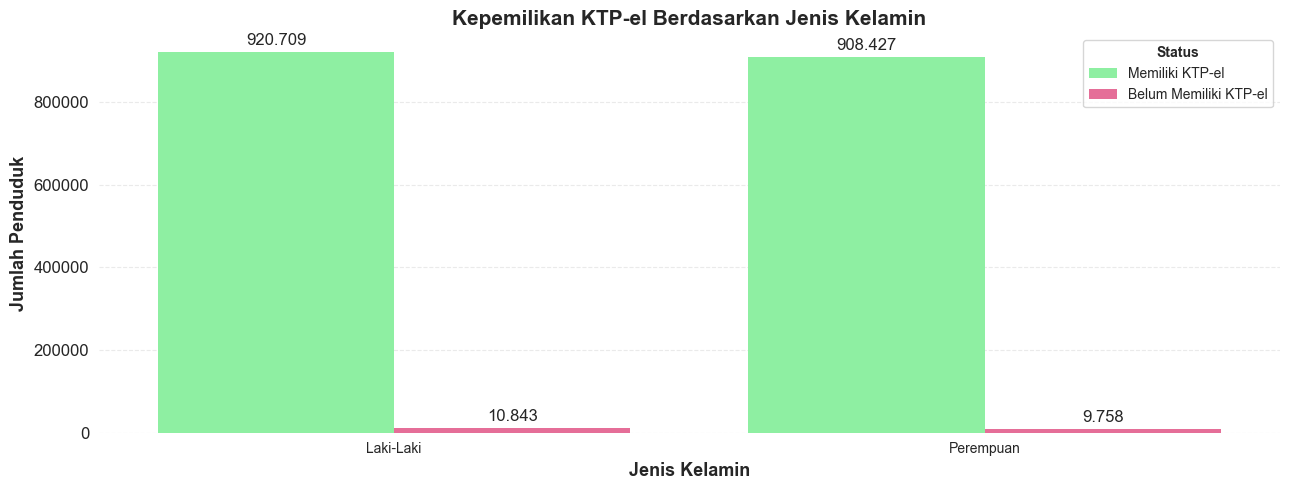

In [107]:
gender_ktp = pd.DataFrame({
    "Jenis Kelamin": ["Laki-Laki", "Perempuan"],
    "Memiliki KTP-el": [
        df["KTP_LK"].sum(),
        df["KTP_PR"].sum()
    ],
    "Belum Memiliki KTP-el": [
        df["BLM_KTP_LK"].sum(),
        df["BLM_KTP_PR"].sum()
    ]
})

gender_long = gender_ktp.melt(
    id_vars="Jenis Kelamin",
    var_name="Status",
    value_name="Jumlah"
)

ax = sns.barplot(
    data=gender_long,
    x="Jenis Kelamin",
    y="Jumlah",
    hue="Status",
    palette={
        "Memiliki KTP-el": "#7EFF98",
        "Belum Memiliki KTP-el": "#F95A92"
    },
    edgecolor="none"
)

plt.title("Kepemilikan KTP-el Berdasarkan Jenis Kelamin", fontsize=15, fontweight="bold")
plt.xlabel("Jenis Kelamin", fontsize=13, fontweight="bold")
plt.ylabel("Jumlah Penduduk", fontsize=13, fontweight="bold")
plt.yticks(fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.4)

for p in ax.patches:
    tinggi = p.get_height()
    if tinggi > 0:
        ax.annotate(
            f"{tinggi:,.0f}".replace(",", "."),
            (p.get_x() + p.get_width() / 2, tinggi),
            ha="center",
            va="bottom",
            fontsize=12,
            xytext=(0, 3),
            textcoords="offset points"
        )

sns.despine(
    ax=ax,
    left=True,
    bottom=True
)

# Keterangan
legend = plt.legend(
    title="Status",
    loc="upper right",
    frameon=True
)
legend.get_title().set_fontweight("bold")

plt.tight_layout()
#plt.savefig("grafik_5_kepemilikan_ktp_berdasarkan_jenis_kelamin.png", dpi=300, bbox_inches="tight")
plt.show()

## G. Grafik 6 : Top 3 Teratas dan 3 Terbawah Belum Memiliki KTP-el Terbanyak

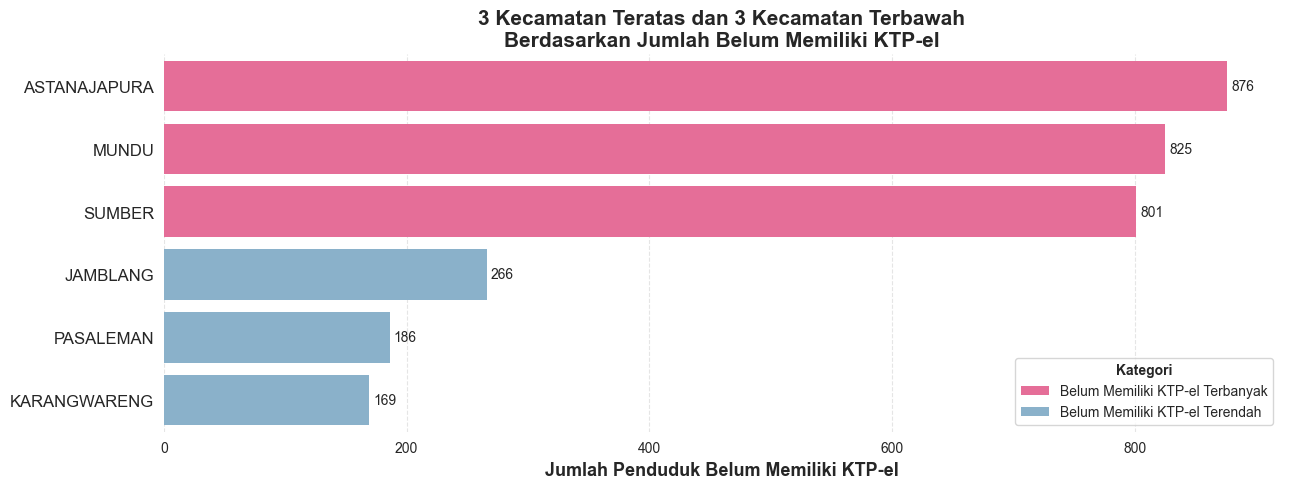

In [106]:
top3_blm_ktp = df.sort_values(
    "BLMKTP",
    ascending=False
).head(3)
top3_blm_ktp["Kategori"] = "Belum Memiliki KTP-el Terbanyak"

bottom3_blm_ktp = df.sort_values(
    "BLMKTP",
    ascending=True
).head(3)
bottom3_blm_ktp["Kategori"] = "Belum Memiliki KTP-el Terendah"

grafik_6 = pd.concat([
    top3_blm_ktp,
    bottom3_blm_ktp
])

grafik_6 = grafik_6.sort_values(
    "BLMKTP",
    ascending=False
)

plt.figure()

ax = sns.barplot(
    data=grafik_6,
    x="BLMKTP",
    y="KECAMATAN",
    hue="Kategori",
    palette={
        "Belum Memiliki KTP-el Terbanyak" : "#F95A92",
        "Belum Memiliki KTP-el Terendah" : "#7FB3D5"
    },
    edgecolor="none"
)

sns.despine(
    ax=ax,
    left=True,
    bottom=True
)

plt.title(
    "3 Kecamatan Teratas dan 3 Kecamatan Terbawah"
    "\nBerdasarkan Jumlah Belum Memiliki KTP-el",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Jumlah Penduduk Belum Memiliki KTP-el", fontsize=13, fontweight="bold")
plt.ylabel("")
plt.yticks(fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)

for p in ax.patches:
    lebar = p.get_width()
    if lebar > 0:
        ax.annotate(
            f"{lebar:,.0f}".replace(",", "."),
            (lebar, p.get_y() + p.get_height() / 2),
            va="center",
            fontsize=10,
            xytext=(3, 0),
            textcoords="offset points"
        )

# Keterangan
legend = plt.legend(
    title="Kategori",
    frameon=True
)
legend.get_title().set_fontweight("bold")

plt.tight_layout()
#plt.savefig("grafik_6_3_teratas_3_terbawah_blm_ktp.png", dpi=300, bbox_inches="tight")
plt.show()